<a href="https://colab.research.google.com/github/mpfunzel-beep/Assignments/blob/main/Applied_Question_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

10-fold CV RMSE:
Cubic spline           4.345758
Polynomial degree 3    4.378078
Polynomial degree 2    4.380108
Linear                 4.932310
dtype: float64


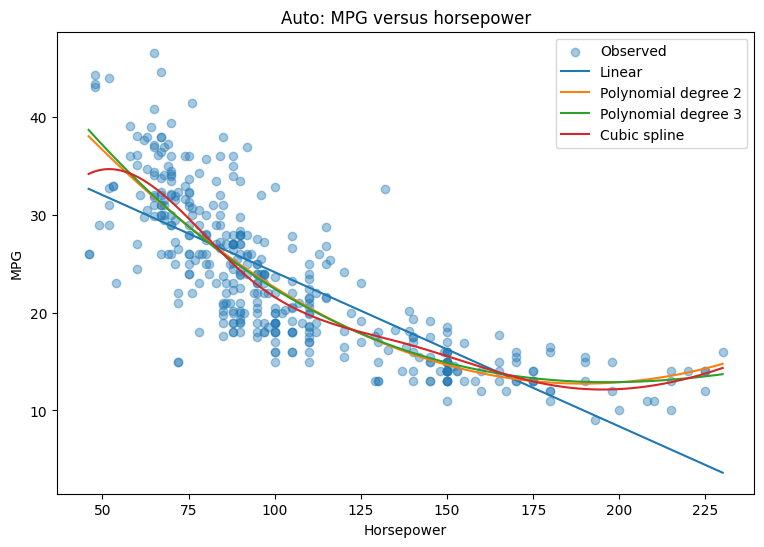

   df_resid          ssr  df_diff     ss_diff           F        Pr(>F)
0     390.0  9385.915872      0.0         NaN         NaN           NaN
1     389.0  7442.029412      1.0  1943.88646  101.608283  2.196340e-21


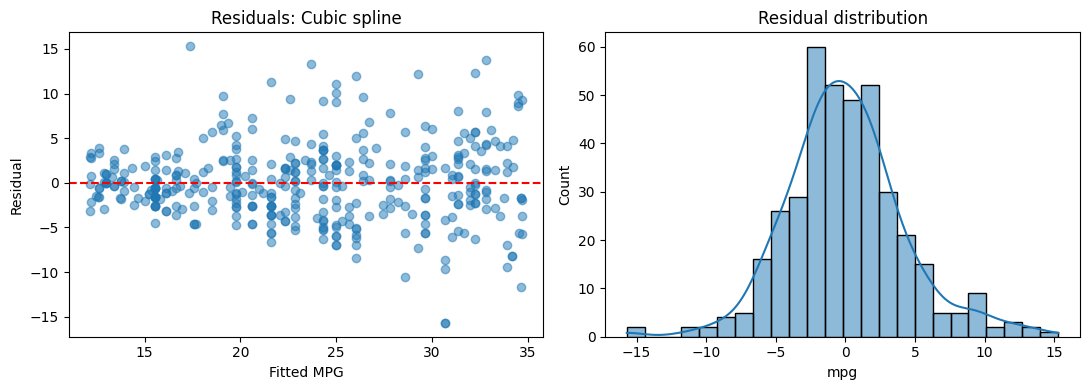

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

%pip install ISLP
from ISLP import load_data
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import statsmodels.formula.api as smf

auto = load_data("Auto").dropna(subset=["mpg", "horsepower"]).copy()

X = auto[["horsepower"]]
y = auto["mpg"]

cv = KFold(n_splits=10, shuffle=True, random_state=4)

models = {
    "Linear": make_pipeline(LinearRegression()),
    "Polynomial degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),
    "Polynomial degree 3": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        LinearRegression()
    ),
    "Cubic spline": make_pipeline(
        SplineTransformer(n_knots=5, degree=3, include_bias=False),
        LinearRegression()
    ),
}

cv_rmse = {}
for name, model in models.items():
    scores = cross_val_score(
        model, X, y, cv=cv,
        scoring="neg_mean_squared_error"
    )
    cv_rmse[name] = np.sqrt(-scores.mean())

print("10-fold CV RMSE:")
print(pd.Series(cv_rmse).sort_values())

# Fit and plot all curves
grid = pd.DataFrame({
    "horsepower": np.linspace(X.horsepower.min(), X.horsepower.max(), 300)
})

plt.figure(figsize=(9, 6))
plt.scatter(X.horsepower, y, alpha=0.4, label="Observed")
for name, model in models.items():
    model.fit(X, y)
    plt.plot(grid.horsepower, model.predict(grid), label=name)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.legend()
plt.title("Auto: MPG versus horsepower")
plt.show()

# Nested-model test: does a quadratic term improve on a linear fit?
linear_fit = smf.ols("mpg ~ horsepower", data=auto).fit()
quadratic_fit = smf.ols(
    "mpg ~ horsepower + I(horsepower ** 2)", data=auto
).fit()
print(sm.stats.anova_lm(linear_fit, quadratic_fit))

# Residual diagnostic for the best CV model
best_name = min(cv_rmse, key=cv_rmse.get)
best_model = models[best_name]
best_model.fit(X, y)
resid = y - best_model.predict(X)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(best_model.predict(X), resid, alpha=0.5)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set(xlabel="Fitted MPG", ylabel="Residual",
          title=f"Residuals: {best_name}")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set(title="Residual distribution")
plt.tight_layout()
plt.show()